# v2.1.5 - Manual clustering: choosing K for the most distinct pathways

Version 2 of notebook 1.5, up to "all clusters on one map". It asks: **which K
gives the largest number of pathways that are clearly different from each other
and come back every time** - including the eastward retroflection.

**Why 1.5 found almost only north-west pathways (K=50 gave 1 eastward centroid,
K=150 gave 2):**

1. 1.5 fits on `complete` particles only (reached 2000 km). Eastward particles
   are mostly `partial` (their track ends before 2000 km): only ~7% of them are
   `complete`, so the fit barely sees them.
2. k-means puts clusters where particles are dense. ~86% of particles leave the
   1000 km circle heading north-west, ~3% have any eastward component, so even
   with 150 clusters almost all of them go to the north-west route.

**What this notebook changes:**

* fits on `complete` + `partial` (`FIT_STATUS`);
* **balanced subsample**: particles are drawn with a weight that depends on
  how common their outer direction is (direction crossing point -> 2000 km exit,
  or last position, in 15-degree sectors). `BALANCE_ALPHA = 1` = draw as they
  come (as in 1.5), `0` = every direction sector equally, `0.5` in between.
  Rare routes then get enough particles to get their own clusters. Only the
  *fit* sample is balanced: notebook 03 still labels every particle;
* counts **distinct pathways** for each K: centroid tracks are joined
  (complete linkage) when their mean distance over the radii is below
  `PATHWAY_SEP_KM`, so two pathways are always at least that far apart;
* checks **reproducibility**: the fit is repeated with other random samples
  and seeds; a pathway counts as real if a pathway within `MATCH_KM` appears in
  every other run.

**What the data contain (run_2, checked on the tracks, 2026-10-21):**

* there is **no equatorward pathway** in run_2: after crossing 2.5N, 0.02% of
  particles ever go back south of 2.5N east of 45W and none south of 1N; the
  2.3% that never cross 2.5N are held near the river mouth (1S-2N, 50-47W)
  for the whole 185 days and never go east of 40W;
* the **eastward retroflection exists** but is small: ~0.6% of particles go
  east of 40W south of 10N, ~3% leave the 1000 km circle with an eastward
  component.

**First result (sweep run 2026-10-21, 3 seeds, separation 400 km):**
`BALANCE_ALPHA = 0`, K = 400 gave 23-26 pathways, 96-100% reproduced
(K = 300: 21 in every run; K = 500: no more pathways, less reproducible;
without balancing at most ~18). The cells below recompute this.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # project root: config.py, pipeline.py
import numpy as np
import pandas as pd
import config as C
import pipeline as P
print("project root:", C.PROJECT_ROOT)
print(f"crossing: {C.LAT_CROSS} N | radii (km): {C.RADII_KM}")

import time
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

project root: /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/kmeans_radius
crossing: 2.5 N | radii (km): [200, 500, 1000, 1500, 2000]


In [2]:
K_SWEEP = [50, 100, 150, 200, 250, 300, 400, 500]   # K values to try
SEEDS = [42, 1, 7]               # repeated fits (different sample + seed) for reproducibility
BALANCE_ALPHA = 0.0              # 1 as they come, 0 every direction sector equally
PATHWAY_SEP_KM = 400             # two pathways differ if their tracks are >= this far apart (mean over radii)
MATCH_KM = 200                   # a pathway is reproduced if another run has one within this distance
N_SUB = 500_000                  # particles per fit
K = None                         # final K; None -> chosen automatically from the sweep
SAVE_MODEL = False               # True -> write the final fit for notebooks 03 / 04

In [3]:
FIT_STATUS = ["complete", "partial"]
SECTOR_DEG = 15
RADIUS_WEIGHTS = dict(C.RADIUS_WEIGHTS)      # tune here; paste into config when final
W = P.feature_weight_vector(RADIUS_WEIGHTS)
print("radii:", C.RADII_KM, "| weights:", RADIUS_WEIGHTS, "| balance alpha:", BALANCE_ALPHA,
      "| separation:", PATHWAY_SEP_KM, "km")

radii: [200, 500, 1000, 1500, 2000] | weights: {200: 1.5, 500: 2, 1000: 1.0, 1500: 1.5, 2000: 1} | balance alpha: 0.0 | separation: 400 km


## Particles to fit, and their outer direction

In [4]:
features = pd.read_parquet(C.FEATURES_FILE)
fitset = features[features.status.isin(FIT_STATUS)].reset_index(drop=True)
del features
R_OUT = C.RADII_KM[-1]
bearing = P.bearing_deg(fitset.cross_lat, fitset.cross_lon,
                        fitset[P.lat_col(R_OUT)], fitset[P.lon_col(R_OUT)])
sector = np.clip(np.floor((bearing + 180) / SECTOR_DEG).astype(int), 0, 360 // SECTOR_DEG - 1)
n_sector = np.bincount(sector, minlength=360 // SECTOR_DEG)
X_all = P.build_feature_matrix(fitset)

tab = pd.DataFrame({"particles": n_sector,
                    "%": (100 * n_sector / n_sector.sum()).round(3)},
                   index=pd.Index([f"{-180 + SECTOR_DEG*i:+4d}..{-180 + SECTOR_DEG*(i+1):+4d}"
                                   for i in range(len(n_sector))], name="direction (deg, 0 N, -90 W)"))
print(f"{len(fitset):,} particles ({', '.join(FIT_STATUS)})")
print(tab[tab.particles > 0].to_string())

def balanced_sample(seed):
    rng = np.random.default_rng(seed)
    w = n_sector[sector].astype(float) ** (BALANCE_ALPHA - 1.0)
    return rng.choice(len(fitset), size=min(N_SUB, len(fitset)), replace=False, p=w / w.sum())

idx0 = balanced_sample(SEEDS[0])
print(f"\nshare with an eastward outer direction: all {100*(bearing > 0).mean():.1f}%, "
      f"in a balanced sample {100*(bearing[idx0] > 0).mean():.1f}%")

15,068,653 particles (complete, partial)
                             particles       %
direction (deg, 0 N, -90 W)                   
-165..-150                           1   0.000
-150..-135                           1   0.000
 -90.. -75                           1   0.000
 -75.. -60                      171888   1.141
 -60.. -45                     9278146  61.572
 -45.. -30                     3960236  26.281
 -30.. -15                     1024693   6.800
 -15..  +0                      276417   1.834
  +0.. +15                      119790   0.795
 +15.. +30                       85780   0.569
 +30.. +45                       68389   0.454
 +45.. +60                       43196   0.287
 +60.. +75                       31748   0.211
 +75.. +90                        7733   0.051
 +90..+105                         581   0.004
+105..+120                          46   0.000
+120..+135                           4   0.000
+135..+150                           2   0.000
+150..+165         


share with an eastward outer direction: all 2.4%, in a balanced sample 40.7%


## Helpers: fit, centroids in degrees, distinct pathways
Centroids in degrees are the mean member position per radius. Track distance =
mean haversine distance between two centroids' exit points over the radii.

In [5]:
def track_dist(A, B):
    nr = A.shape[1] // 2
    D = 0
    for j in range(nr):
        D = D + P.haversine_km(A[:, None, 2*j], A[:, None, 2*j+1], B[None, :, 2*j], B[None, :, 2*j+1])
    return D / nr

def fit_k(k, idx, seed, n_init=10):
    X = X_all[idx]
    sc = StandardScaler().fit(X)
    km = MiniBatchKMeans(n_clusters=k, random_state=seed, batch_size=10000,
                         n_init=n_init, max_iter=300).fit(sc.transform(X) * W)
    cent = pd.DataFrame(X).groupby(km.labels_).mean().reindex(range(k)).to_numpy()
    return km, sc, cent

def pathways(cent):
    # flat groups of centroids; every pair of groups is >= PATHWAY_SEP_KM apart
    Z = linkage(squareform(track_dist(cent, cent), checks=False), "complete")
    g = fcluster(Z, t=PATHWAY_SEP_KM, criterion="distance") - 1
    return g, np.array([cent[g == i].mean(axis=0) for i in range(g.max() + 1)])

def is_east(tracks, start_lon):
    return P.bearing_deg(C.LAT_CROSS, start_lon, tracks[:, -2], tracks[:, -1]) > 0

## Sweep K: number of distinct pathways and their reproducibility
For every K and seed: fit, group the centroids into pathways, count them (and
the eastward ones), and check whether each pathway reappears in the other runs.

In [6]:
start_all = fitset.cross_lon.to_numpy()
rows, runs = [], {}
for k in K_SWEEP:
    for seed in SEEDS:
        t0 = time.time()
        idx = balanced_sample(seed)
        km_s, sc_s, cent = fit_k(k, idx, seed)
        g, ptrack = pathways(cent)
        slon = pd.Series(start_all[idx]).groupby(km_s.labels_).mean().reindex(range(k)).to_numpy()
        pstart = np.array([slon[g == i].mean() for i in range(g.max() + 1)])
        runs[(k, seed)] = ptrack
        rows.append(dict(K=k, seed=seed, pathways=len(ptrack),
                         east=int(is_east(ptrack, pstart).sum()), sec=round(time.time() - t0)))
    for seed in SEEDS:                       # reproducibility of each run's pathways
        others = [runs[(k, s)] for s in SEEDS if s != seed]
        ok = np.all([track_dist(runs[(k, seed)], o).min(axis=1) < MATCH_KM for o in others], axis=0)
        next(r for r in rows if r["K"] == k and r["seed"] == seed)["reproduced_%"] = round(100 * ok.mean())
    print(f"K={k:4d}: " + ", ".join(f"{r['pathways']} ({r['east']} east, {r['reproduced_%']}%)"
                                     for r in rows if r["K"] == k), flush=True)
sweep = pd.DataFrame(rows)
summary = sweep.groupby("K")[["pathways", "east", "reproduced_%"]].agg(["mean", "min", "max"]).round(1)
summary

K=  50: 11 (5 east, 91%), 11 (6 east, 82%), 12 (7 east, 67%)


K= 100: 14 (7 east, 93%), 15 (9 east, 93%), 13 (7 east, 92%)


K= 150: 17 (10 east, 100%), 19 (11 east, 95%), 16 (9 east, 100%)


K= 200: 18 (11 east, 89%), 17 (9 east, 94%), 16 (9 east, 94%)


K= 250: 21 (13 east, 100%), 19 (12 east, 89%), 22 (13 east, 100%)


K= 300: 21 (11 east, 95%), 21 (13 east, 90%), 21 (12 east, 100%)


K= 400: 26 (16 east, 100%), 23 (15 east, 96%), 23 (14 east, 96%)


K= 500: 24 (15 east, 100%), 25 (16 east, 88%), 24 (17 east, 96%)


pathways          east         reproduced_%         
        mean min max  mean min max         mean min  max
K                                                       
50      11.3  11  12   6.0   5   7         80.0  67   91
100     14.0  13  15   7.7   7   9         92.7  92   93
150     17.3  16  19  10.0   9  11         98.3  95  100
200     17.0  16  18   9.7   9  11         92.3  89   94
250     20.7  19  22  12.7  12  13         96.3  89  100
300     21.0  21  21  12.0  11  13         95.0  90  100
400     24.0  23  26  15.0  14  16         97.3  96  100
500     24.3  24  25  16.0  15  17         94.7  88  100

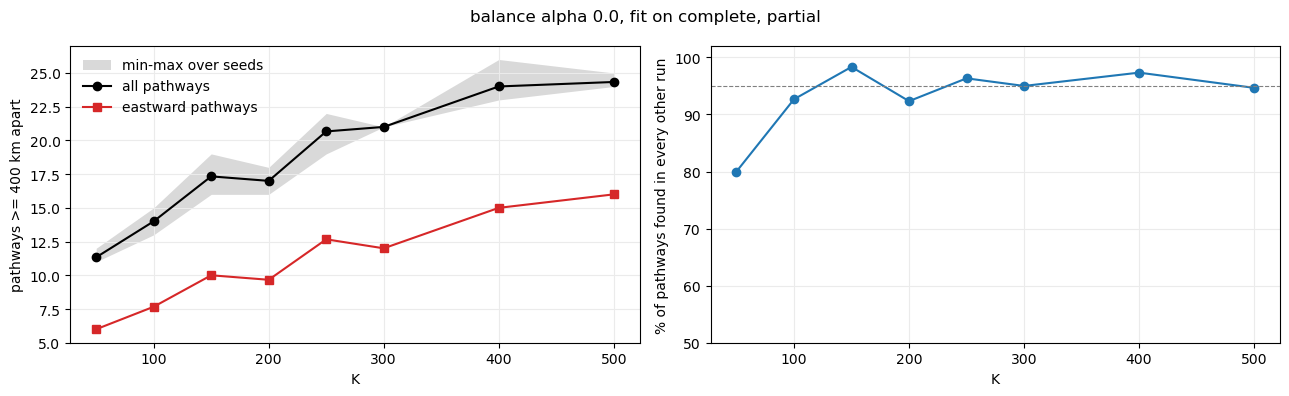

suggested K = 400: 24.0 pathways (15.0 eastward), 97% reproduced
K used below: 400


In [7]:
s = sweep.groupby("K").agg(p=("pathways", "mean"), pmin=("pathways", "min"), pmax=("pathways", "max"),
                           e=("east", "mean"), r=("reproduced_%", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].fill_between(s.index, s.pmin, s.pmax, color="0.85", lw=0, label="min-max over seeds")
ax[0].plot(s.index, s.p, "o-", color="k", label="all pathways")
ax[0].plot(s.index, s.e, "s-", color="tab:red", label="eastward pathways")
ax[0].set_xlabel("K"); ax[0].set_ylabel(f"pathways >= {PATHWAY_SEP_KM} km apart")
ax[0].legend(frameon=False); ax[0].grid(color="0.92")
ax[1].plot(s.index, s.r, "o-", color="tab:blue")
ax[1].axhline(95, color="0.5", ls="--", lw=.8)
ax[1].set_xlabel("K"); ax[1].set_ylabel("% of pathways found in every other run")
ax[1].set_ylim(50, 102); ax[1].grid(color="0.92")
fig.suptitle(f"balance alpha {BALANCE_ALPHA}, fit on {', '.join(FIT_STATUS)}"); fig.tight_layout(); plt.show()

# choice: most pathways among the K whose pathways are >= 95% reproduced (smaller K on ties)
good = s[s.r >= 95]
K_AUTO = int((good if len(good) else s).sort_values(["p", "r"], ascending=[False, False]).index[0])
print(f"suggested K = {K_AUTO}: {s.loc[K_AUTO, 'p']:.1f} pathways "
      f"({s.loc[K_AUTO, 'e']:.1f} eastward), {s.loc[K_AUTO, 'r']:.0f}% reproduced")
if K is None:
    K = K_AUTO
print("K used below:", K)

## Final fit at K
Same balanced sample as the first seed, more initialisations. The pathway of
each cluster (`PATH_OF`) and the share of ALL particles in each pathway (from
labelling a random 2 million) are what the next steps of 1.5 build on.

In [8]:
idx = balanced_sample(SEEDS[0])
sub = fitset.iloc[idx].reset_index(drop=True)
km, scaler, cent_deg = fit_k(K, idx, SEEDS[0], n_init=20)
labels = km.labels_
sizes = np.bincount(labels, minlength=K)
start_lon = sub.groupby(labels).cross_lon.mean().reindex(range(K)).to_numpy()
def centroid_track(c):
    return (np.r_[start_lon[c], cent_deg[c, 1::2]],
            np.r_[C.LAT_CROSS, cent_deg[c, 0::2]])

PATH_OF, ptrack = pathways(cent_deg)
n_path = len(ptrack)
pstart = np.array([start_lon[PATH_OF == i].mean() for i in range(n_path)])
p_east = is_east(ptrack, pstart)

ps = np.random.default_rng(0).choice(len(fitset), size=min(2_000_000, len(fitset)), replace=False)
lab_ps = km.predict(scaler.transform(X_all[ps]) * W)
share = 100 * np.bincount(PATH_OF[lab_ps], minlength=n_path) / len(ps)
cl_count = np.bincount(lab_ps, minlength=K)          # real particles per cluster (in the 2M sample)
ptab = pd.DataFrame({"clusters": np.bincount(PATH_OF, minlength=n_path),
                     "% of all particles": share.round(3), "eastward": p_east,
                     f"exit lat {R_OUT}km": ptrack[:, -2].round(1),
                     f"exit lon {R_OUT}km": ptrack[:, -1].round(1)})
ptab.index.name = "pathway"
print(f"fit K={K} on {len(sub):,} particles (balanced) | {n_path} pathways, "
      f"{int(p_east.sum())} eastward | cluster sizes {sizes.min()}..{sizes.max()}")
ptab.sort_values("% of all particles", ascending=False)

fit K=400 on 500,000 particles (balanced) | 25 pathways, 15 eastward | cluster sizes 144..11120


,clusters,% of all particles,eastward,exit lat 2000km,exit lon 2000km
pathway,,,,,
5,46,63.563,False,13.4,-64.2
0,31,17.518,False,15.3,-60.7
1,38,7.853,False,16.3,-56.6
2,19,2.014,False,16.9,-54.6
4,13,1.996,False,11.4,-53.4
11,36,1.956,False,14.4,-51.0
6,7,1.849,False,6.9,-56.7
8,16,0.634,False,10.2,-49.8
12,25,0.454,True,11.3,-46.3


In [9]:
# Persist THIS fit for notebooks 03 / 04 (only when SAVE_MODEL is True).
import joblib, json
if SAVE_MODEL:
    MODEL_DIR = C.manual_model_dir(K)
    if MODEL_DIR.exists():
        print("NOTE: overwriting", MODEL_DIR)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump(km, MODEL_DIR / f"kmeans_k{K}.pkl")
    joblib.dump(scaler, MODEL_DIR / "scaler.pkl")
    np.save(MODEL_DIR / "weights_W.npy", W)
    np.save(MODEL_DIR / "centroids_deg.npy", cent_deg)
    np.save(MODEL_DIR / "pathway_of_cluster.npy", PATH_OF)
    sub[["trajectory_id", "store", "row", "traj"]].assign(cluster=labels).to_parquet(
        MODEL_DIR / "subsample_labels.parquet", index=False)
    sweep.to_csv(MODEL_DIR / "k_sweep.csv", index=False)
    (MODEL_DIR / "fit_metadata.json").write_text(json.dumps(dict(
        source_notebook="v2.1.5_Manual_clustering.ipynb", K=K, LAT_CROSS=C.LAT_CROSS,
        RADII_KM=C.RADII_KM, RADIUS_WEIGHTS={str(k): v for k, v in RADIUS_WEIGHTS.items()},
        FIT_STATUS=FIT_STATUS, BALANCE_ALPHA=BALANCE_ALPHA, SECTOR_DEG=SECTOR_DEG,
        PATHWAY_SEP_KM=PATHWAY_SEP_KM, n_pathways=int(n_path), N_SUB=N_SUB,
        seed=SEEDS[0], n_fitted=int(len(sub)), cluster_sizes=sizes.tolist()), indent=2))
    print("saved model ->", MODEL_DIR)
else:
    print("SAVE_MODEL is False -> nothing written")

SAVE_MODEL is False -> nothing written


## Cheap coastline

In [10]:
import matplotlib.patches as mpatches

def draw_refs(ax, **kw):
    # reference lines from the day-based notebooks + the 2.5N starting line
    for x in (-70, -60, -40):
        ax.axvline(x, lw=.5, **kw)
    ax.axhline(20, lw=.5, **kw)
    ax.axhline(C.LAT_CROSS, lw=.6, ls="--", color="k")
    ax.add_patch(mpatches.Rectangle(xy=(-55, 5), width=10, height=5, lw=1,
                                    edgecolor="green", facecolor="none"))

import cartopy.feature as cfeature
lon_lim = (C.DOMAIN["lon_min"], C.DOMAIN["lon_max"])
lat_lim = (C.DOMAIN["lat_min"], C.DOMAIN["lat_max"])
_coast = []
for geom in cfeature.COASTLINE.with_scale("110m").geometries():
    for line in getattr(geom, "geoms", [geom]):
        _coast.append((np.asarray(line.xy[0]), np.asarray(line.xy[1])))
def draw_coast(ax):
    for x, y in _coast:
        ax.plot(x, y, "-", color="0.75", lw=.4, zorder=0)
    ax.set_xlim(*lon_lim); ax.set_ylim(*lat_lim)

## All clusters on one map
Top left: every centroid track, coloured by its pathway. The other three
panels draw one line per pathway in three ways (label = pathway number and its
share of all particles; line width ~ share; red = eastward):

* **plain mean** of the pathway's centroids (every cluster counts the same);
* **size-weighted mean**: each centroid weighted by how many real particles
  it gets when a random 2 million particles are labelled, so big clusters
  count more (the fit sample was balanced, so cluster sizes in the fit do not
  show how common a route is);
* **representative cluster**: the real centroid of the pathway whose track is
  closest, on average, to all the others in it - a track that some cluster
  actually has, not an average of several.

Zigzags in the eastward lines come from particles whose track ends before
1500 / 2000 km: their "exit" there is the last position, which can lie inside
the circle.

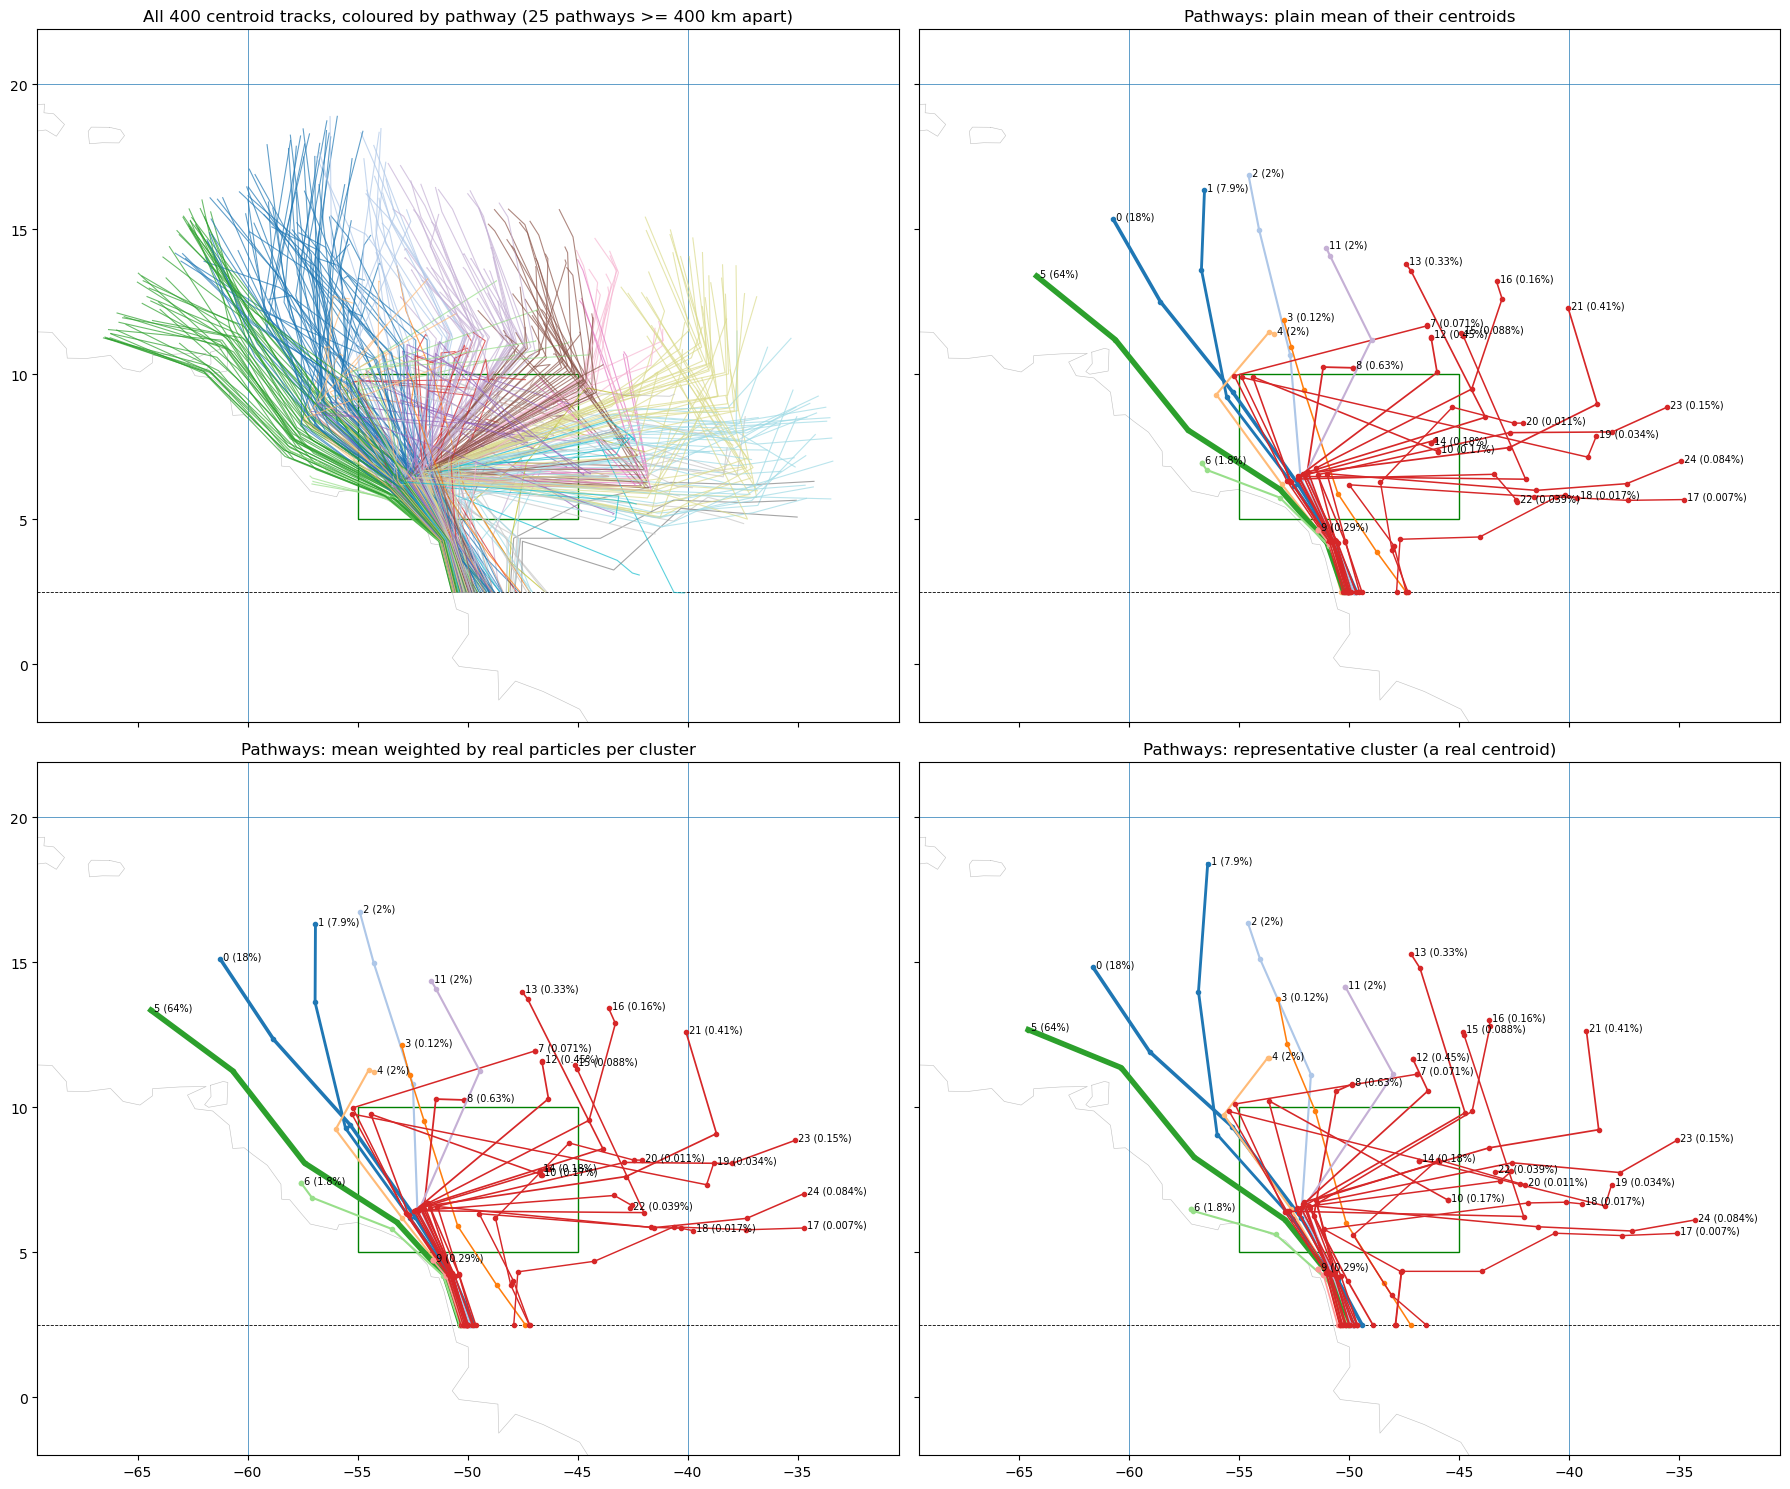

,% of particles,clusters,representative cluster,plain vs weighted [km],plain vs representative [km],weighted vs representative [km]
pathway,,,,,,
5,63.563,46,6,12.0,41.0,44.0
0,17.518,31,111,23.0,47.0,31.0
1,7.853,38,156,19.0,67.0,70.0
2,2.014,19,253,21.0,42.0,40.0
4,1.996,13,338,42.0,40.0,63.0
11,1.956,36,99,43.0,59.0,98.0
6,1.849,7,139,69.0,52.0,61.0
8,0.634,16,181,25.0,59.0,70.0
12,0.454,25,112,33.0,62.0,36.0


In [11]:
def mean_tracks(weights):
    tr, st = [], []
    for i in range(n_path):
        m = PATH_OF == i
        w = weights[m] if weights[m].sum() > 0 else np.ones(m.sum())
        tr.append(np.average(cent_deg[m], axis=0, weights=w))
        st.append(np.average(start_lon[m], weights=w))
    return np.array(tr), np.array(st)

def representative_tracks():
    tr, st, rep = [], [], []
    for i in range(n_path):
        mem = np.where(PATH_OF == i)[0]
        D = track_dist(cent_deg[mem], cent_deg[mem])
        c = mem[D.mean(axis=1).argmin()]        # closest on average to the other members
        tr.append(cent_deg[c]); st.append(start_lon[c]); rep.append(c)
    return np.array(tr), np.array(st), np.array(rep)

tr_plain, st_plain = mean_tracks(np.ones(K))
tr_wmean, st_wmean = mean_tracks(cl_count.astype(float))
tr_rep, st_rep, REP_OF = representative_tracks()

pcmap = plt.get_cmap("tab20", max(n_path, 3))
la_all = np.r_[cent_deg[:, 0::2].ravel(), C.LAT_CROSS]; lo_all = cent_deg[:, 1::2].ravel()
zoom = (lo_all.min() - 3, lo_all.max() + 3, min(la_all.min(), 0) - 2, la_all.max() + 3)

def draw_pathways(ax, tracks, starts, title):
    draw_coast(ax); draw_refs(ax)
    for i in range(n_path):
        lo = np.r_[starts[i], tracks[i, 1::2]]; la = np.r_[C.LAT_CROSS, tracks[i, 0::2]]
        ax.plot(lo, la, ".-", color="tab:red" if p_east[i] else pcmap(i),
                lw=1 + 3 * np.sqrt(share[i] / share.max()), zorder=3)
        ax.text(lo[-1], la[-1], f" {i} ({share[i]:.2g}%)", fontsize=7, zorder=4)
    ax.set_title(title)

fig, axes = plt.subplots(2, 2, figsize=(18, 15), sharex=True, sharey=True)
ax = axes[0, 0]
draw_coast(ax); draw_refs(ax)
for c in range(K):
    lo, la = centroid_track(c)
    ax.plot(lo, la, "-", color=pcmap(PATH_OF[c]), lw=.8, alpha=.7, zorder=2)
ax.set_title(f"All {K} centroid tracks, coloured by pathway ({n_path} pathways "
             f">= {PATHWAY_SEP_KM} km apart)")
draw_pathways(axes[0, 1], tr_plain, st_plain, "Pathways: plain mean of their centroids")
draw_pathways(axes[1, 0], tr_wmean, st_wmean, "Pathways: mean weighted by real particles per cluster")
draw_pathways(axes[1, 1], tr_rep, st_rep, "Pathways: representative cluster (a real centroid)")
for a in axes.ravel():
    a.set_xlim(zoom[0], zoom[1]); a.set_ylim(zoom[2], zoom[3])
fig.tight_layout(); plt.show()

# how far apart the three versions are, per pathway (mean over radii, km)
diff = pd.DataFrame({
    "% of particles": share.round(3), "clusters": np.bincount(PATH_OF, minlength=n_path),
    "representative cluster": REP_OF,
    "plain vs weighted [km]": np.diag(track_dist(tr_plain, tr_wmean)).round(0),
    "plain vs representative [km]": np.diag(track_dist(tr_plain, tr_rep)).round(0),
    "weighted vs representative [km]": np.diag(track_dist(tr_wmean, tr_rep)).round(0)},
    index=pd.Index(range(n_path), name="pathway"))
diff.sort_values("% of particles", ascending=False)